# Inference speed, memory, and accuracy comparison

Benchmark the three models trained under our shared conditions: U-Net-ResNet18
(CNN), SegFormer-B0 (transformer), and UNetFormer-ResNet18 (hybrid). Use their
existing best augmented-run SUIM checkpoints; no models are trained here.
The authors' original pretrained U-Net remains a separate reference.

All models use batch size **1**, **320 x 240** RGB inputs, FP32 parameters and
inputs, evaluation mode, and inference mode with autocast disabled. Notebook
padding, full-resolution upsampling, sigmoid, and strict > 0.5 thresholding are
included. Each model's five output masks must match its saved evaluation masks
exactly before timing.

The same 106 TEST images excluding known exact training-pool overlaps are used
for speed and the accompanying saved accuracy scores. No settings or checkpoints
are selected using these scores.

## Timing protocol

Three rounds rotate the model order so each model runs first, second, and third
once. Every model/round uses a fresh process, one CPU Torch thread, 30 warm-up
predictions, and three timed passes over all 106 images: **954 samples per model
per timing phase**. Startup, checkpoint loading, correctness checks, and warm-up
are excluded.

Two phases are measured:

- **GPU-ready prediction:** input is already on the GPU. Synchronized wall time
  includes model execution, padding/upsampling, sigmoid, thresholding, CPU kernel
  dispatch, and timer instrumentation. Output remains on the GPU. CUDA event
  timings for the same work are also saved separately.
- **Image-to-mask pipeline:** warm-cache image file loading/decoding, bicubic
  resizing, ImageNet normalization, transfer to GPU, prediction, and transfer of
  five binary masks to CPU. Mask encoding/saving and metric computation are
  excluded.

FPS is 1,000 divided by mean latency in milliseconds at batch 1. This is a serial
prediction rate, not an overlapping or larger-batch throughput benchmark.
Median and p95 latency, individual samples, and variation across rounds are saved.

FP32 follows the existing notebook's backend policy: matmul TF32 is disabled,
cuDNN TF32 is allowed. Actual flags are recorded per worker. cuDNN benchmarking
is disabled and deterministic algorithms are requested by the notebook config;
no compilation, export, FP16, or other deployment optimization is added.

## Environment and running

Use **Python (SUIM U-Net ResNet18)**, the existing `.venv-segformer` GPU environment.
The runner reads model definitions and strict checkpoint loaders from notebooks
03, 04, and 05. It does not execute training or overwrite their saved predictions.
Results overwrite `artifacts/speed_comparison/`; the small smoke check uses its
separate `smoke/` subfolder.

From the project root:

```powershell
.\.venv-segformer\Scripts\python.exe scripts\benchmark_inference.py
```

This notebook defaults to reading completed results. Set `RUN_BENCHMARK = True`
to measure again. Close other active GPU workloads before repeating measurements.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/benchmark_inference.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the SUIM project.')
sys.path.insert(0, str(ROOT / 'scripts'))
from benchmark_inference import LABELS
OUTPUT_DIR = ROOT / 'artifacts/speed_comparison'


In [2]:
RUN_BENCHMARK = False
ROUNDS = 3
PASSES = 3
WARMUP = 30

In [3]:
if RUN_BENCHMARK:
    subprocess.run([sys.executable, str(ROOT / 'scripts/benchmark_inference.py'),
                    '--root', str(ROOT), '--rounds', str(ROUNDS),
                    '--passes', str(PASSES), '--warmup', str(WARMUP)], check=True, cwd=ROOT)
else:
    print('Reading saved speed results. No training or new benchmark is started.')

Reading saved speed results. No training or new benchmark is started.


## Results

Latency is milliseconds per image; lower is better. FPS is images per second;
higher is better. Accuracy uses the same five-class per-image IoU and boundary
F-score as our previous notebooks, not eight-class confusion-matrix mIoU.

In [4]:
summary = json.loads((OUTPUT_DIR / 'summary.json').read_text(encoding='utf-8'))
status = json.loads((OUTPUT_DIR / 'status.json').read_text(encoding='utf-8'))
assert summary['completed'] and not summary['smoke'] and status['state'] == 'complete'
comparison = pd.read_csv(OUTPUT_DIR / 'comparison.csv')
print('GPU:', comparison.gpu.iloc[0])
print('Batch size: 1 | Input: 320 x 240 | Precision: FP32 (recorded TF32 backend defaults)')
print('Rounds:', summary['rounds'], '| Passes per round:', summary['passes_per_round'],
      '| Images per pass:', summary['images_per_pass'])
display(comparison[['label', 'prediction_mean_ms', 'prediction_median_ms', 'prediction_p95_ms',
                    'prediction_fps', 'image_to_mask_mean_ms', 'image_to_mask_fps',
                    'round_prediction_mean_std_ms', 'round_image_to_mask_mean_std_ms']].round(3))
display(comparison[['label', 'parameters_million', 'peak_allocated_mib',
                    'peak_reserved_mib', 'iou_pct', 'boundary_f_pct']].round(3))
print('The GPU memory columns describe this worker, not total GPU memory reported by nvidia-smi.')

GPU: NVIDIA GeForce RTX 3070 Laptop GPU
Batch size: 1 | Input: 320 x 240 | Precision: FP32 (recorded TF32 backend defaults)
Rounds: 3 | Passes per round: 3 | Images per pass: 106


,label,prediction_mean_ms,prediction_median_ms,prediction_p95_ms,prediction_fps,image_to_mask_mean_ms,image_to_mask_fps,round_prediction_mean_std_ms,round_image_to_mask_mean_std_ms
0,U-Net-ResNet18 (CNN),7.956,7.009,10.866,125.695,17.369,57.575,0.843,2.932
1,SegFormer-B0,16.425,14.675,23.862,60.884,27.033,36.991,0.530,4.424
2,UNetFormer-ResNet18 (hybrid),14.724,13.380,20.677,67.919,22.370,44.702,0.951,0.195


,label,parameters_million,peak_allocated_mib,peak_reserved_mib,iou_pct,boundary_f_pct
0,U-Net-ResNet18 (CNN),14.329,87.581,112.0,57.953,51.658
1,SegFormer-B0,3.715,66.536,80.0,53.113,46.859
2,UNetFormer-ResNet18 (hybrid),11.725,66.926,94.0,57.359,52.923


The GPU memory columns describe this worker, not total GPU memory reported by nvidia-smi.


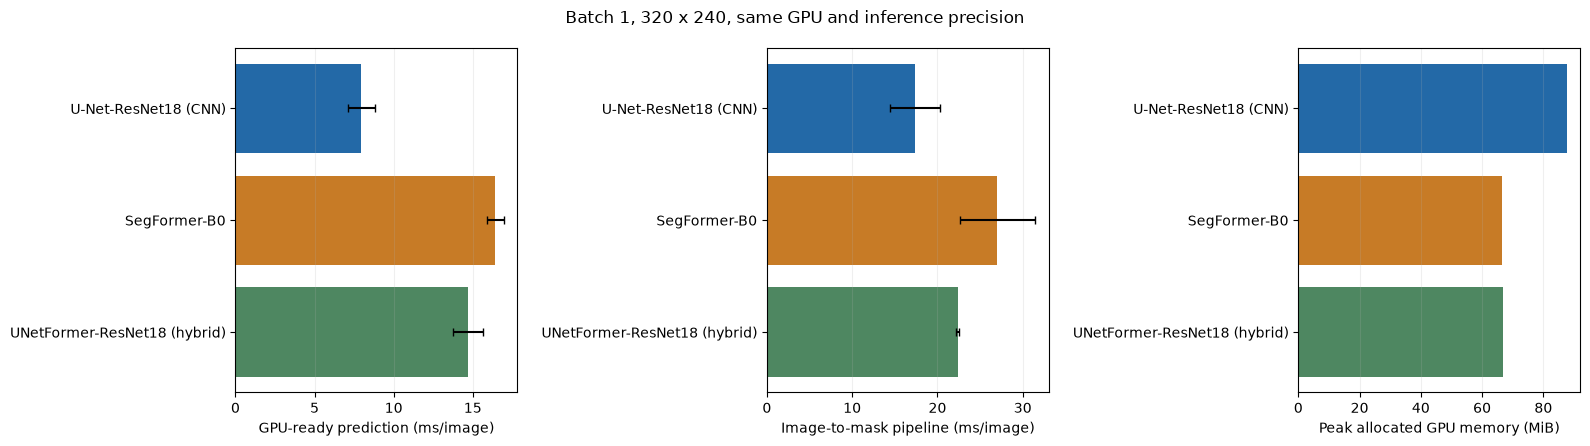

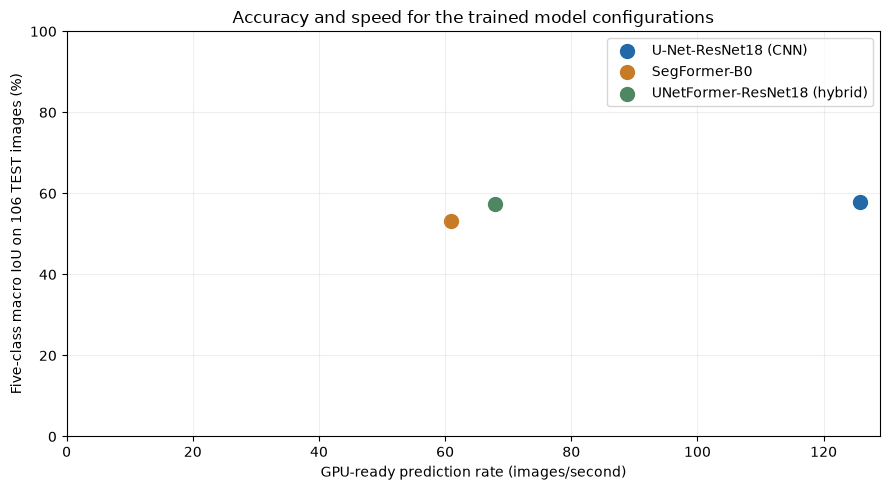

In [5]:
colors = ['#2369a7', '#c77b26', '#4e8761']
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, column, title in zip(axes,
    ['prediction_mean_ms', 'image_to_mask_mean_ms', 'peak_allocated_mib'],
    ['GPU-ready prediction (ms/image)', 'Image-to-mask pipeline (ms/image)', 'Peak allocated GPU memory (MiB)']):
    error = (comparison.round_prediction_mean_std_ms if column == 'prediction_mean_ms'
             else comparison.round_image_to_mask_mean_std_ms if column == 'image_to_mask_mean_ms' else None)
    axis.barh(comparison.label, comparison[column], color=colors, xerr=error, capsize=3)
    axis.invert_yaxis()
    axis.set_xlabel(title)
    axis.grid(axis='x', alpha=0.2)
figure.suptitle('Batch 1, 320 x 240, same GPU and inference precision')
figure.tight_layout()
figure.savefig(OUTPUT_DIR / 'latency_memory_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

figure, axis = plt.subplots(figsize=(9, 5))
for (_, row), color in zip(comparison.iterrows(), colors):
    axis.scatter(row.prediction_fps, row.iou_pct, s=100, color=color, label=row.label)
axis.set_xlabel('GPU-ready prediction rate (images/second)')
axis.set_ylabel('Five-class macro IoU on 106 TEST images (%)')
axis.set_title('Accuracy and speed for the trained model configurations')
axis.set_ylim(0, 100)
axis.set_xlim(left=0)
axis.grid(alpha=0.2)
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / 'accuracy_speed_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## Interpretation and limits

Peak allocated memory is the maximum GPU tensor allocation observed for one
model in a fresh worker: weights, batch-1 input, intermediate tensors, and binary
output. Reserved memory includes PyTorch's caching allocator pool. These figures
exclude the CUDA context, other applications, and the rest of system memory.
Parameter counts include every stored model parameter, including the hybrid's
training auxiliary head even though it is inactive during inference.

These results describe the current eager PyTorch implementations on this laptop.
They do not establish a universal speed ordering for CNNs, transformers, or
hybrids. GPU power, clocks, temperature, background activity, software versions,
input size, batching, and deployment optimizations can change timings. Per-worker
GPU telemetry, software versions, source/checkpoint hashes, and raw samples are
saved. Accuracy comes from single-seed training runs; repeated timing rounds do
not add independent training seeds.

Timing follows PyTorch's [CUDA synchronization guidance](https://docs.pytorch.org/docs/2.8/notes/cuda.html)
and [CUDA Event API](https://docs.pytorch.org/docs/2.8/generated/torch.cuda.Event.html).
Memory uses the documented [peak tensor allocation API](https://docs.pytorch.org/docs/2.8/generated/torch.cuda.memory.max_memory_allocated.html).
Model provenance and licenses remain in the source notebooks and repository
license files.

## Findings from this benchmark

The CNN had the lowest GPU-ready mean latency (**7.96 ms**, **125.7 images/s**),
followed by the hybrid (**14.72 ms**, **67.9 images/s**) and SegFormer-B0
(**16.42 ms**, **60.9 images/s**). The warm-cache image-to-mask rates were
**57.6**, **44.7**, and **37.0 images/s**, respectively.

SegFormer-B0 had the fewest parameters (**3.72 million**) and lowest peak tensor
allocation (**66.54 MiB**). The hybrid used **11.72 million** parameters and
**66.93 MiB**; the CNN used **14.33 million** and **87.58 MiB**. Parameter counts
alone did not predict speed for these implementations.

Together with the saved accuracy results, the CNN had the highest IoU and was
fastest in this setup. The hybrid had the highest boundary F-score. SegFormer
was the most compact model by parameter count. These conclusions describe our
trained configurations and timing protocol on this laptop, rather than all
models in each architecture family. Round-to-round variation is shown in the
error bars and the table; it is especially noticeable in image-to-mask timings.